## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Amelia Chen

**Date:** 10/19/2026

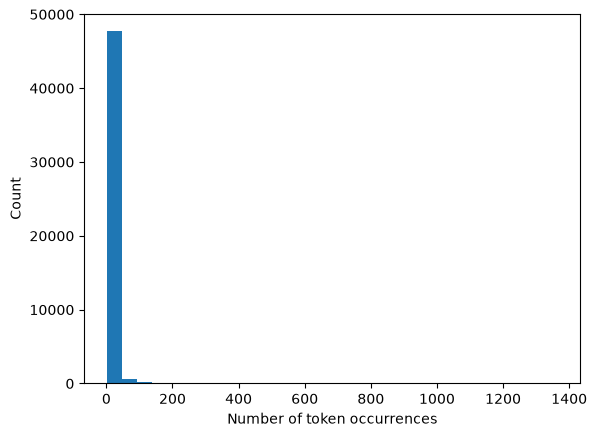

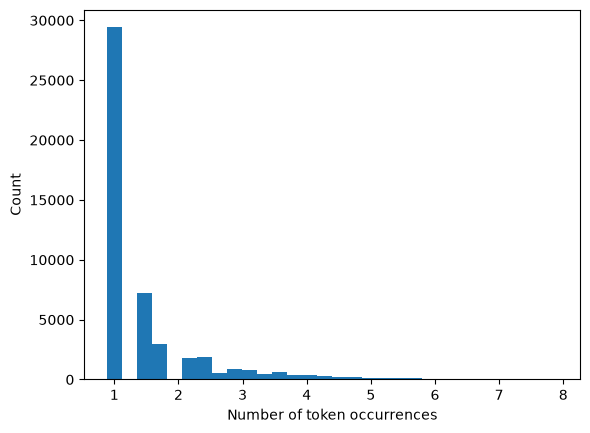

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598), ('online', 591), ('need', 587), ('wrote:', 585), ('see', 554), ('conference', 553), ('language', 550), ('want', 548), ('empty', 546), ('hourahead', 526), ('list', 523), ('attached', 515), ('hello', 501), ('university', 500), ('2001', 489), ('information', 473), ('vince', 473), ('may', 461), ('good', 449), ('following', 448), ('hour', 446), ('2000', 442), ('business', 442), ('save', 423), ('first', 423), ('click', 423), ('best', 423), ('make', 421), ('com', 413), ('original', 410), ('offer', 405), ('meeting', 403), ('thanks', 397), ('mail', 395), ('use', 389), ('find', 386), ('papers', 383), ('http', 378), ('sent', 375), ('available', 373), ('last', 372), ('update', 363)

In [46]:
########## ========== Q1 ========== ##########

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# plot a histogram of the occurances of tokens
token_counts = list(token_count.values())
plt.figure()
plt.hist(token_counts, bins=30)
plt.xlabel("Number of token occurrences")
plt.ylabel("Count")
plt.savefig("token_counts_histogram.png")
plt.show()


token_counts_arcsinh = np.arcsinh(token_counts)
plt.figure()
plt.hist(token_counts_arcsinh, bins=30)
plt.xlabel("Number of token occurrences")
plt.ylabel("Count")
plt.savefig("token_counts_arcsinh_histogram.png")
plt.show()

print(token_freq)
print()
print(token_freq[::-1])

##### What do you notice about the frequency of occurrence of different tokens? How does it look?

The first histogram I plotted was very badly scaled: there is a bar that reaches towards the top of the graph in the left side, then it falls immediately to close to the bottom of the bar. The next bin is barely a sliver above the bottom of the graph. I plotted a second histogram with an arcsinh transformation to get a better look at the shape. In this second graph, we see the tail of the graph much clearer. There is still a very tall bar at the left side of the graph, but the immediate drop appears less steep. The tail extends quite long, especially after the ~2.5 mark on the x-axis, the histogram very gradually tapers off.

We can see in the first histogram that the x-axis extends all the way to 1400. However, because of the scale, and the very small count, we cannot see anything at x=1400. Even in the arcsinh transformed histogram, the histogram extends to 8 on the x-axis but nothing is visible there. This points to the existance of a small number of tokens that occurs extremely frequently in emails. The number of token occurnaces is very high, but there is not many tokens that occur this often, which is why its not visible to us. On the other hand, there are a very large amount of tokens which don't occur very freuquently in emails. In the first histogram, the first bin ends around number of token occurances = 50. This means that an overwhelming majority of tokens, nearly 50,000 tokens, occur in emails less than or equal to 50 times. 

I used the provided token_freq variable to take a closer look at the specific numbers. I printed the list first in descending order, then in ascending order. The numbers explain the trends we were seeing in the histogram: the token "new" occurs 1365 times, "date" occurs 1202 times, "get" occurs 1052 times, and "please" occurs 1022 times. These tokens have extrememly high occurance in emails, however these four are the only tokens that occur more than 1000 times. Looking at the list in ascending order, we see that there are a lot of tokens that only occur once. This makes sense logically as there are so many possible unique tokens that may only ever occur once in emails- we see that some tokens are very long urls or obscure words or incomprehensible strings.

In [ ]:
########## ========== Q2 ========== ##########

# Sources:
# https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf
# https://scikit-learn.org/1.5/auto_examples/linear_model/plot_ols.html 
# https://www.statology.org/sklearn-regression-coefficients/

'''Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens 
and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's 
a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails.
'''

from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import r2_score

filepath = 'data/Phishing_clean.parquet'
df = pd.read_parquet(filepath)

# print(df.head(5))

X = df.drop(columns = ["Email Type"])   # remove email type column, which is the y, from the X variable
y = df["Email Type"]    # only the email type column is the y variable to be predicted

# split the data with 20% test size
(
    X_train,
    X_test,
    y_train,
    y_test,
) = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# create and fit the linear regression model, predict it on both the training and the testing data
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)
y_train_pred =regr.predict(X_train)
y_test_pred = regr.predict(X_test)

# calculate the R^2 scores of both the training and test datasets
print("R2 of training set: ", r2_score(y_train, y_train_pred))
print("R2 of test set: ", r2_score(y_test, y_test_pred))
print()

# put the absolute value of coefficients in a dataframe and associate them with their corresponding token
# print the top 10 tokens/coefficients
coefficients = pd.DataFrame(zip(X_train.columns, regr.coef_), columns=["token", "coef"])
coefficients["coef"] = coefficients["coef"].abs()
print(coefficients.sort_values(by="coef", ascending=False).head(20))

R2 of training set:  0.7677733084118992
R2 of test set:  0.6571173475409775

                                                  token      coef
906                                               aging  0.996514
1406                                         helvetica,  0.892177
740                                           localized  0.787934
1504                                  background-image:  0.780070
2362                                            thermal  0.671019
2058                                              12px;  0.629280
2365                                                rcs  0.553536
1810                                          exercise!  0.542180
1511                                            burning  0.515023
2094                                           #000000;  0.502902
2666                                           #331f30;  0.502902
2532                                             xanaax  0.500298
818                                                cnet  0.492166

##### What is the $R^2$ on the test set? On the training set?
The R^2 of the training set is ~0.768, and the R^2 of the test set is ~0.657. Since the R^2 of the training set is better, it indicates that the model captures the variation of the training data better than it does the testing data.

##### What words have the largest coefficients in absolute value and most strongly influence predictions? 

The top 10 words that have the largest coefficients in aboslute value are "aging", "helvetica,", "localized", "background-image", "thermal" "12px", "rcs", "exercise!", "burning", and "#000000". "Aging" has by far the largest coefficient of 0.996514. When we remove the absolute value, we see that the coefficient was originally positive. This means that the inclusion of the word "aging" in an email is an extremely strong influence on classifying an email as a scam. There is a pretty steady drop in the coefficient values, and by the time we have reached the 10th largest coefficient, the coefficient value has dropped to 0.502902. When we look at the top 20 largest coefficients, we see that the decreasing coefficient values become less steep. From the top 10 to top 20 largest coefficients, we only drop from 0.502902 to 0.444397. Since we are looking at the absolute value, we cannot tell which values are influencing the model to predict scam/not scam, we only see that these are the most influential tokens in general.

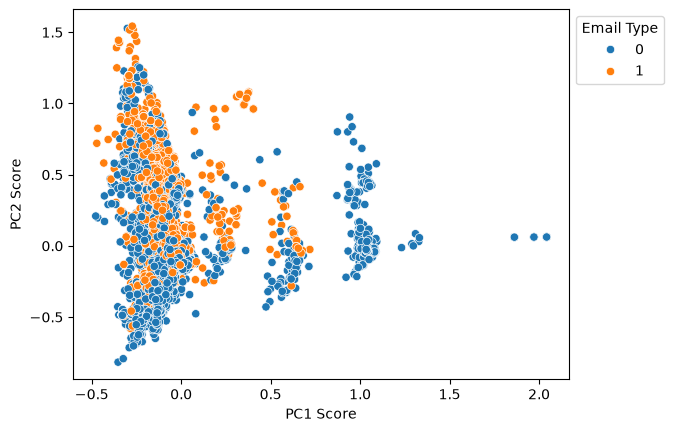

In [26]:
########## ========== Q3 ========== ##########

# Sources: https://www.geeksforgeeks.org/machine-learning/implementing-pca-in-python-with-scikit-learn/

'''
Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a 
principal components analysis decomposition with two components. Plot the first two principal components in 
a scatter plot, and hue the points by whether they are a phishing scam or not.
'''

from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

plt.figure()
ax = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y)
plt.xlabel("PC1 Score")
plt.ylabel("PC2 Score")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("pca_scatterplot.png")
plt.show()


##### Do you notice any patterns?

I notice that in our scatterplot, there are some clusters that have formed. There is one very large cluster that falls between -0.5-0.0 on the PC1 score axis, and extends all the way across the entire length of the PC2 score axis, from -0.5 to 1.5. In this cluster, it seems to appear that emails classified as not a scam tend to have a lower PC2 score, while emails classified as a scam tend to have a higher PC2 score. We observe more email type 1 at the top end of the graph and email type 0 at the bottom end of the graph, however, there is a lot of overlap throughout the entire cluster. The email types seem roughly even, there isn't one type that dominates.

There are three other clusters which are much smaller but have the same vertical shape, roughly extending from PC2 Score= -0.3-0.5. One cluster formed around PC1 score = 0.25, another around 0.6, and another around 1.0. The small cluster at PC1 score=0.25 also contains quite a bit of overlap, but similarly to the large cluster there are more email type 0 points towards the lower end of the cluster and vice versa. Again, the proportion of email types seem quite even. Above this cluster there are quite a few email type 1 points, however they are a bit sparse and don't form a distinct cluster. The second cluster seems to have slightly more non scam emails, and the third cluster is completely non scam emails. There are three points which appear very far away from the other points, they have a high PC1 score of around 2.0 and a PC2 score of around 0.1. These points are all non scam emails.

Due to the majority of the points being in one cluster, and the very high amount of overlap in that one cluster, it seems that both scam and non scam emails share similar features in PC1 but encompass a wide variety of features in PC2. Overall, non-scam emails cover a wide variety of features in PC1, while scam emails contain a smaller segment of those captured variations in PC1. Aside from the cluster that formed around PC1 score=1.0, which contained only non scam emails, it is quite difficult to distinguish between scam/non-scam emails with these two components.

In [52]:
########## ========== Q4 ========== ##########

'''
Run a linear regression of $y$ on the first 2,610 principal components of $X$. 
What is the $R^2$ on the training and test sets?
'''

pca_all = PCA(n_components=2610).fit(X)

X_train_pca = pca_all.fit_transform(X_train)
X_test_pca = pca_all.transform(X_test)

# create and fit the linear regression model, predict it on both the training and the testing data
regr = linear_model.LinearRegression()
regr.fit(X_train_pca, y_train)

y_train_pred_pca =regr.predict(X_train_pca)
y_test_pred_pca = regr.predict(X_test_pca)

# calculate the R^2 scores of both the training and test datasets
print("R2 of training set: ", r2_score(y_train, y_train_pred_pca))
print("R2 of test set: ", r2_score(y_test, y_test_pred_pca))


R2 of training set:  0.766896761127783
R2 of test set:  0.6613559301353331


##### How does this performance compare to the linear regression?

The R^2 score of the training set for linear regression was ~0.768, while the R^2 score of the training set for linear regression of PCA was ~0.767. The R^2 score of the test set for linear regression was ~0.657, while the R^2 score of the test set for linear regression of PCA was ~0.661. Overall, the performances are very similar. For the performance on the training data, the R^2 score differed by only 0.001. For the test data, regression of PCA was greater by a small difference of 0.004. Similarly to linear regression, using PCA also performed a bit better on the training data compared to the testing data.

##### Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The advantage of using principal components for high-dimensional regression is that we can reduce the dimensions of the data while preserving the most important parts of the information: the variance. It may help us remove redundancy in the original data if there are some features which are correlated in the same way, allowing us to represent that relationship with a reduced number of principal components rather than all the features. The information that is left is the variance between features, which reflect the underlying patterns in how the features are related to each other. This allows us to make computation more efficient and potentially visualize the data in 2 or 3D.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7b06ac16d28082b4615711a6435c3743e64db737
- **AI tool and model used:** Claude Sonnet 5.5 Medium effort

### *Prompts used

1. Hi Claude, can you check my code and written responses for accuracy and give me concise bullet points on fixes/improvements? [code/responses]
2. (follow up prompt based on suggestion 5) Can you explain what you mean when you say large coefficients aren't necessarily most influential?

### *AI-proposed changes


1. PCA(n_components=2610).fit(X) is redundant because fit_transform(X_train) refits immediately. Drop the first fit, since it was fit on the full data including test.
2. Scatterplot: hue=y with 0/1 values can give an awkward legend. Mapping the labels to “Scam”/”Not scam” is clearer.
3. Token frequency: “occur in emails ≤50 times” should say “occur ≤50 times in total across the corpus.” Counter counts occurrences, not the number of emails containing a token. This is a heavy-tailed, Zipf-like distribution, and naming it would sharpen the answer.
4. Coefficient sign contradiction: you say “aging” was positive when the absolute value is removed, but your code discards the sign. Then you say you “cannot tell” which words push toward scam. Pick one, and recompute the signed coefficients to confirm.
5. Coefficient interpretation: Large coefficients don’t mean “most influential” in a practical sense. These tokens appear in only a few emails (≥15), so their coefficients are unstable. Noisy, rare-feature coefficients are a symptom of overfitting, which fits your train R² (0.768) vs test R² (0.657) gap. Say that explicitly.
6. PCA scatterplot: Your two summaries disagree. One says both classes have “similar features in PC1,” the other says non-scam emails “cover a wide variety in PC1” while scam emails cover less. PC scores aren’t “features”; they’re linear combinations of words. “Classified as” should be “labeled as,” since these are true labels, not predictions.
7. PCA vs. OLS comparison: the near-identical R² isn’t just a coincidence. 2,610 of 2,711 components is nearly a full rotation of the original space, so the fit is almost the same as OLS. The tiny differences come from dropping the 101 lowest-variance components, which acts as slight regularization (slightly lower train R², slightly higher test R²).
8. Advantage of PCA: “Preserving the most important parts: the variance” is imprecise. PCA is unsupervised, so high variance doesn’t guarantee predictive value for y. The key advantages for regression are orthogonal predictors (no multicollinearity) and the option to drop low-variance directions to reduce overfitting.

- **response to follow up prompt**: 

Both statements are partly true. A large coefficient does mean the word has a big effect when it’s present, but that’s different from having a big effect on predictions overall.

What a coefficient measures

Each feature is 0/1 (word absent or present). The coefficient is how much the predicted value changes when that word is present, holding the other words fixed. A coefficient of ~1 for “aging” means that if “aging” appears, the model’s prediction jumps by about 1, which is the whole gap between “not scam” (0) and “scam” (1).

Why that isn’t the same as overall influence

Frequency matters. A word’s total effect on predictions depends on its coefficient and how many emails contain it. A word with a coefficient of 0.99 that appears in 15 emails changes 15 predictions. A word with a coefficient of 0.1 that appears in 2,000 emails changes far more.
Rare words give unstable coefficients. Every word in this dataset appears in at least 15 emails, so the biggest coefficients may come from words near that minimum. If a word shows up only in scam emails, even by chance, OLS can assign it a huge coefficient. That’s fitting noise rather than a reliable signal, and it connects to your train vs. test R² gap (0.768 vs. 0.657).
Correlated words share credit. When words co-occur (like “helvetica”, “12px”, “background-image”, which are all HTML/CSS styling), OLS can split or inflate their coefficients in ways that aren’t individually meaningful.

The question likely just wants the words with the largest absolute coefficients, which you already have. I’d add two or three sentences: these words shift the prediction the most when present, but they may be rare, so their coefficients are noisy and their overall effect on predictions may be small, which is consistent with the overfitting you see in the R² gap.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I see that in my original code I am calling pca_all = PCA(n_components=2610).fit(X) then immediately calling X_train_pca = pca_all.fit_transform(X_train), which just overrides the initial fit. Claude is correct in that it is redundant, and I also see that we would not want to fit the PCA on all of the X values as we want to split the training and text X. Luckily, this was just a simple redundancy and didn't affect the output of the code. |
| 2 | Accept | While this suggestion is not an error, I agree it would help the scatterplot be easier to read if the legend describes scam/non scam emails rather than the 0/1 mapping.  |
| 3 | Accept | While I initially already understood that the occurances are counting each instance and not each email instance, I can see how my wording might be confusing. I agree that Claude's suggestion to clarify the entire corpus is more clear.  |
| 4 | Accept | I included the sentence about "aging" have a positive coefficient and thus an influence towards scam, just as something I was curious about since the coefficient was so high. But since it wasn't explicity included as a part of the question it would probably make more sense not to include it. |
| 5 | Accept | I asked Claude to explain further what it meant that large coefficients are not necessarily the most influential. It explained that the presence of a certain token may have a very strong influence on whether or not a certain email is labeled as a scam or not a scam, but if that token only appears the minimum of 15 times, it has only a big impact on those specific email predictions and not predictions overall. I do think Claude was correct when it said that the question seems to be only asking about the largest coefficients, but I think this is a nuance worth mentioning. I also think that connecting it to the R^2 differences in the previous question is a significant observation. |
| 6 | Accept | I was trying to say that the majority of points, both scam and not scam, have similar features in PC1 which is shown in the large cluster, however overall non scam emails do stretch along the entire length of PC1 scores while scam is depicted in a smaller segment. I understand how my wording is somewhat contradictory. I will edit my writing to specify between the majority observation and general observation.  |
| 7 | Accept / modify / reject | ... |
| 8 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

##### Suggestion 1

In [53]:
########## ========== Q4 ========== ##########

'''
Run a linear regression of $y$ on the first 2,610 principal components of $X$. 
What is the $R^2$ on the training and test sets?
'''

pca_all = PCA(n_components=2610)    # removed redundant .fit(X)

X_train_pca = pca_all.fit_transform(X_train)
X_test_pca = pca_all.transform(X_test)

# create and fit the linear regression model, predict it on both the training and the testing data
regr = linear_model.LinearRegression()
regr.fit(X_train_pca, y_train)

y_train_pred_pca =regr.predict(X_train_pca)
y_test_pred_pca = regr.predict(X_test_pca)

# calculate the R^2 scores of both the training and test datasets
print("R2 of training set: ", r2_score(y_train, y_train_pred_pca))
print("R2 of test set: ", r2_score(y_test, y_test_pred_pca))

R2 of training set:  0.766896761127783
R2 of test set:  0.6613559301353331


##### Suggestion 2

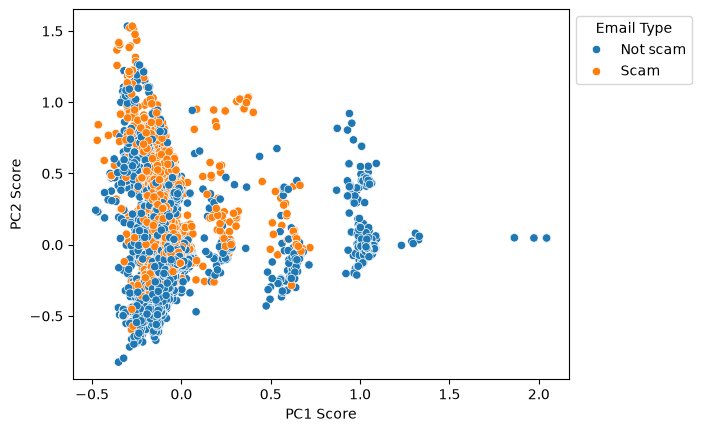

In [54]:
########## ========== Q3 ========== ##########

# Sources: https://www.geeksforgeeks.org/machine-learning/implementing-pca-in-python-with-scikit-learn/

'''
Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a 
principal components analysis decomposition with two components. Plot the first two principal components in 
a scatter plot, and hue the points by whether they are a phishing scam or not.
'''

from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

labels = y.map({0: "Not scam", 1: "Scam"})

plt.figure()
ax = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels)
plt.xlabel("PC1 Score")
plt.ylabel("PC2 Score")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.savefig("pca_scatterplot.png")
plt.show()

##### Suggestion 3

##### What do you notice about the frequency of occurrence of different tokens? How does it look?

The first histogram I plotted was very badly scaled: there is a bar that reaches towards the top of the graph in the left side, then it falls immediately to close to the bottom of the bar. The next bin is barely a sliver above the bottom of the graph. I plotted a second histogram with an arcsinh transformation to get a better look at the shape. In this second graph, we see the tail of the graph much clearer. There is still a very tall bar at the left side of the graph, but the immediate drop appears less steep. The tail extends quite long, especially after the ~2.5 mark on the x-axis, the histogram very gradually tapers off.

We can see in the first histogram that the x-axis extends all the way to 1400. However, because of the scale, and the very small count, we cannot see anything at x=1400. Even in the arcsinh transformed histogram, the histogram extends to 8 on the x-axis but nothing is visible there. This points to the existance of a small number of tokens that occurs extremely frequently across the emails. The number of token occurnaces is very high, but there is not many tokens that occur this often, which is why its not visible to us. On the other hand, there are a very large amount of tokens which don't occur very freuquently across the emails. In the first histogram, the first bin ends around number of token occurances = 50. This means that an overwhelming majority of tokens, nearly 50,000 tokens, occur across the entire corpus of emails less than or equal to 50 times. 

I used the provided token_freq variable to take a closer look at the specific numbers. I printed the list first in descending order, then in ascending order. The numbers explain the trends we were seeing in the histogram: the token "new" occurs 1365 times, "date" occurs 1202 times, "get" occurs 1052 times, and "please" occurs 1022 times. These tokens have extrememly high occurance across the emails, however these four are the only tokens that occur more than 1000 times. Looking at the list in ascending order, we see that there are a lot of tokens that only occur once. This makes sense logically as there are so many possible unique tokens that may only ever occur once in emails- we see that some tokens are very long urls or obscure words or incomprehensible strings.

##### Suggestion 4/5

##### What is the $R^2$ on the test set? On the training set?
The R^2 of the training set is ~0.768, and the R^2 of the test set is ~0.657. Since the R^2 of the training set is better, it indicates that the model captures the variation of the training data better than it does the testing data.

##### What words have the largest coefficients in absolute value and most strongly influence predictions? 

The top 10 words that have the largest coefficients in aboslute value are "aging", "helvetica,", "localized", "background-image", "thermal" "12px", "rcs", "exercise!", "burning", and "#000000". "Aging" has by far the largest coefficient of 0.996514. There is a pretty steady drop in the coefficient values, and by the time we have reached the 10th largest coefficient, the coefficient value has dropped to 0.502902. When we look at the top 20 largest coefficients, we see that the decreasing coefficient values become less steep. From the top 10 to top 20 largest coefficients, we only drop from 0.502902 to 0.444397. Since we are looking at the absolute value, we cannot tell which values are influencing the model to predict scam/not scam, we only see that these are the most influential tokens in general. As an additional note to consider, these largest coefficients don't necessarily influence the overall predictions of the model. This is because certain words may appear in majority scam or majority non scam emails, which makes the model treat those specific tokens as stronger indicators of whether or not an email is a scam or not, based on the presence of the token. However, we did not look at the number of occurances of these tokens. Some of them may have very small occurances, possible as little as the 15 minimum, which would mean that they only influence the prediction of a maximum of 15 emails. If the model assigns a high coefficient to tokens that only appear a small number of times, the model is overfitting and learning the noise of the training data, which explains why the R^2 of the training data is notably higher than the performance on the test data.

##### Suggestion 6

##### Do you notice any patterns?

I notice that in our scatterplot, there are some clusters that have formed. There is one very large cluster that falls between -0.5-0.0 on the PC1 score axis, and extends all the way across the entire length of the PC2 score axis, from -0.5 to 1.5. In this cluster, it seems to appear that emails labeled as not a scam tend to have a lower PC2 score, while emails labeled as a scam tend to have a higher PC2 score. We observe more email type 1 at the top end of the graph and email type 0 at the bottom end of the graph, however, there is a lot of overlap throughout the entire cluster. The email types seem roughly even, there isn't one type that dominates.

There are three other clusters which are much smaller but have the same vertical shape, roughly extending from PC2 Score= -0.3-0.5. One cluster formed around PC1 score = 0.25, another around 0.6, and another around 1.0. The small cluster at PC1 score=0.25 also contains quite a bit of overlap, but similarly to the large cluster there are more email type 0 points towards the lower end of the cluster and vice versa. Again, the proportion of email types seem quite even. Above this cluster there are quite a few email type 1 points, however they are a bit sparse and don't form a distinct cluster. The second cluster seems to have slightly more non scam emails, and the third cluster is completely non scam emails. There are three points which appear very far away from the other points, they have a high PC1 score of around 2.0 and a PC2 score of around 0.1. These points are all non scam emails.

Due to the majority of the points being in one cluster, and the very high amount of overlap in that one cluster, it seems that a majority of both scam and non scam emails share similar PC1 scores but have a wide range of PC2 scores. Looking at the graph as a whole, non-scam emails also cover a wider range of PC1 scores, while scam emails contain a smaller segment. Aside from the cluster that formed around PC1 score=1.0, which contained only non scam emails, it is quite difficult to distinguish between scam/non-scam emails with these two components.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

